인공신경망
-nn모듈 : 신경망을 구축하고 학습시키는데 필요한 모든 구성요소를 제공하는 핵심 모듈
-주요 역할 및 구성요소
1. 인공신경망 레이어 (layer): 입력데이터를 변환하는 다양한 층을 제공 
- 선형 레이어(nn.Linear) : 완전연결층 
- 합성곱 레이어 (nn.Conv2d) : 이미지 처리에 쓰이는 cnn레이어 
- 순환 레이어(nn.LTSM, nn.GRU) : 텍스트, 시계열 처리에 쓰는 RNN레이어
2. 활성화 함수 (Activation Functions) : 비선형성을 추가하여 모델이 복잡한 패턴을 학습할 수 있도록 해준다. 
- nn.ReLU(), nn.Sigmoid(), nn.Softmax() 등 
3. 손실 함수 (Loss Functions) : 모델의 예측값과 실제 값의 오차를 계산 
- nn.MESLoss(), nn.CrossEntropyLoss() 등 
4. 컨테이너 : 여러 레이어를 묶어서 하나의 모델로 구조화
- nn.Module : 모든 신경망 모델의 기본 클래스 
- 자신이 만드는 모든 커스텀 모델은 nn.Module를 상속받아 정의하여 사용 
- nn.Sequential : 레이어를 순차적으로 연결해주는 간단한 래퍼임.

In [3]:
import torch
from torch import nn
from torchviz import make_dot

In [ ]:
x = torch.tensor([1.])

model = nn.Linear (1, 1)
print(model)
print()

print(model.weight)
print(model.bias)

y = model(x)
print(y)



Linear(in_features=1, out_features=1, bias=True)

Parameter containing:
tensor([[-0.8770]], requires_grad=True)
Parameter containing:
tensor([-0.0439], requires_grad=True)


In [13]:
fc1 = nn.Linear(1,3)
fc2 = nn.Linear(3,1)

print(fc1.weight)
print(fc1.weight.shape)

x = torch.tensor([1.])

print(fc1.bias)
print(fc1.bias.shape)

print(fc2.weight)
print(fc2.bias)

x = fc1(x)
print(x)

x = torch.tensor([1.])

y2 = (x @ fc1.weight.T + fc1.bias) @ fc2.weight.T + fc2.bias

print(y2)
print(y2)

Parameter containing:
tensor([[-0.4273],
        [-0.2224],
        [ 0.6596]], requires_grad=True)
torch.Size([3, 1])
Parameter containing:
tensor([-0.1969, -0.7684, -0.3185], requires_grad=True)
torch.Size([3])
Parameter containing:
tensor([[-0.3539, -0.2074, -0.3785]], requires_grad=True)
Parameter containing:
tensor([0.1511], requires_grad=True)
tensor([-0.6242, -0.9908,  0.3410], grad_fn=<UnsafeViewBackward0>)
tensor([0.4484], grad_fn=<AddBackward0>)
tensor([0.4484], grad_fn=<AddBackward0>)


feature과 channel의 차이



tensor([ 1.4257, -0.6485])
tensor([1.4925, 1.4856, 0.1179], grad_fn=<UnsafeViewBackward0>)


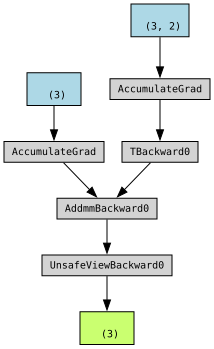

In [ ]:
model = nn.Linear(2,3)
# 2개의 채널을 가진 데이터에 대해 3개의 채널을 가지는 데이터로 변환하는 것 
x = torch.randn(2)
print(x)
print(model(x))

make_dot(model(x))

In [27]:
model = nn.Linear(2,3)
x = torch.randn(5,2)  #2개의 특징(몸무게,키)을 가지는 데이터(사람) 5개(명)
print(x)
print(model(x)) 
x_1 = model(x)
print(x_1.shape)

y = torch.randn(4,5,2)
print(model(y).shape)

z = torch.randn (2,3,6,5,3,2)
print(model(z).shape)

tensor([[ 1.0837,  1.9899],
        [ 0.9442, -2.4154],
        [ 1.0261, -1.3758],
        [ 1.6491,  0.9537],
        [ 0.7816, -0.8052]])
tensor([[-0.5739, -1.9811, -0.4068],
        [ 1.5924, -0.4854, -0.2149],
        [ 1.0850, -0.8723, -0.2729],
        [-0.0188, -2.0442, -0.5167],
        [ 0.7844, -0.8840, -0.2297]], grad_fn=<AddmmBackward0>)
torch.Size([5, 3])
torch.Size([4, 5, 3])
torch.Size([2, 3, 6, 5, 3, 3])


In [30]:
fc1 = nn.Linear(1,3)
fc2 = nn.Linear(3,1)

x = torch.tensor([1.])
x = fc1(x)
y = fc2(x)

model = nn.Sequential(fc1, fc2)
x = torch.tensor([1.])
print(model(x))


tensor([0.1065], grad_fn=<UnsafeViewBackward0>)


In [31]:
model = nn.Sequential(nn.Linear(2,5), 
                      nn.Linear(5,10), 
                      nn.Linear(10,3))

x = torch.randn(7,2)
print(model(x))

tensor([[ 0.4102, -0.3449, -0.0098],
        [ 0.2858, -0.1473, -0.0196],
        [ 0.2516, -0.0959, -0.0367],
        [ 0.2997, -0.1242,  0.2100],
        [ 0.2631, -0.0346,  0.3651],
        [ 0.1896,  0.0075, -0.0167],
        [ 0.2524, -0.0987, -0.0444]], grad_fn=<AddmmBackward0>)


In [ ]:
# 1. Linear 계층 생성
model = nn.Linear(3, 2)

# 2. Weight와 Bias 설정
with torch.no_grad():
    model.weight.copy_(torch.tensor([
        [1., 0., -1.],
        [2., 1.,  0.]
    ]))

    model.bias.copy_(torch.tensor([0.5, -1.]))

# 3. 입력 데이터 생성
x = torch.tensor([
    [1., 2., 3.],
    [2., 0., 1.]
])

# 4. 모델 실행
y = model(x)

# 5. 결과 출력
print("Weight:", model.weight)
print("Weight Shape:", model.weight.shape)

print("Bias:", model.bias)
print("Bias Shape:", model.bias.shape)

print("Input Shape:", x.shape)
print("Output:", y)
print("Output Shape:", y.shape)

In [32]:
# 1. 모델 생성
model = nn.Sequential(
    nn.Linear(4, 6),
    nn.Sigmoid(),
    nn.Linear(6, 3),
    nn.Sigmoid(),
    nn.Linear(3, 2)
)

# 2. 입력 데이터 생성
x = torch.randn(5, 4)

# 3. 모델에 입력하여 출력 계산
y = model(x)

# 4. 입력과 출력 Shape 확인
print("입력 Shape:", x.shape)
print("출력 Shape:", y.shape)

# 5. 각 Linear 계층의 Weight와 Bias Shape 확인
for i, layer in enumerate(model):
    if isinstance(layer, nn.Linear):
        print(f"\nLinear 계층 {i}")
        print("Weight Shape:", layer.weight.shape)
        print("Bias Shape:", layer.bias.shape)

# 6. 전체 학습 가능한 파라미터 개수
total_params = sum(p.numel() for p in model.parameters())

print("\n전체 파라미터 개수:", total_params)

입력 Shape: torch.Size([5, 4])
출력 Shape: torch.Size([5, 2])

Linear 계층 0
Weight Shape: torch.Size([6, 4])
Bias Shape: torch.Size([6])

Linear 계층 2
Weight Shape: torch.Size([3, 6])
Bias Shape: torch.Size([3])

Linear 계층 4
Weight Shape: torch.Size([2, 3])
Bias Shape: torch.Size([2])

전체 파라미터 개수: 59


In [33]:
# 1. 모델 생성
model = nn.Sequential(
    nn.Linear(5, 8),
    nn.ReLU(),
    nn.Linear(8, 2)
)

# 2. 입력 데이터 생성
x = torch.randn(2, 3, 5)

# 3. 모델에 입력하여 출력 계산
y = model(x)

# 4. 입력과 출력 Shape 확인
print("입력 Shape:", x.shape)
print("출력 Shape:", y.shape)

# 5. 전체 학습 가능한 파라미터 개수

입력 Shape: torch.Size([2, 3, 5])
출력 Shape: torch.Size([2, 3, 2])
